<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Week_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
import glob
import math

1. Hasil Inverse Citra:


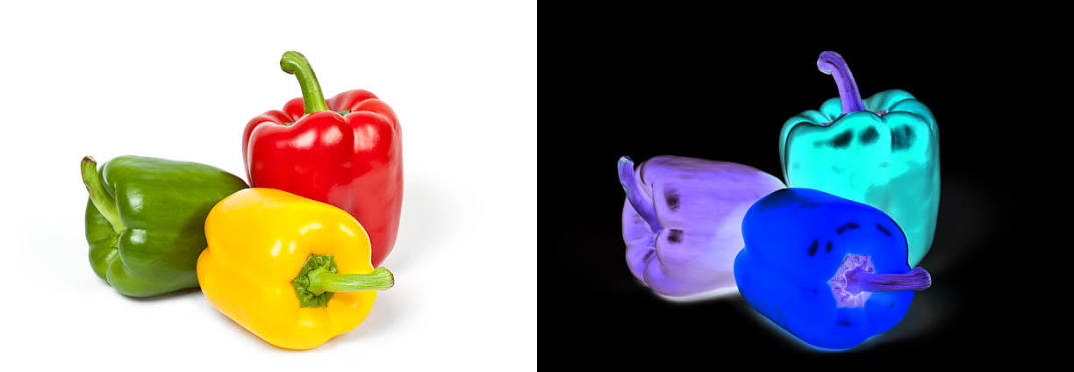

In [ ]:
# TUGAS 1: INVERSE CITRA
# Baca gambar (ganti 'peppers.jpg' sesuai nama file Anda)
img = cv.imread('peppers.jpg')

# Operasi inversi: g(x,y) = 255 - f(x,y)
img_inverse = 255 - img

print("1. Hasil Inverse Citra:")
final_frame_inv = cv.hconcat((img, img_inverse))
cv2_imshow(final_frame_inv)

Masukkan tingkat kecerahan (misal: 10): 9
Masukkan kontras (misal: 1.5): 1.3

2. Hasil Transformasi Contrast:


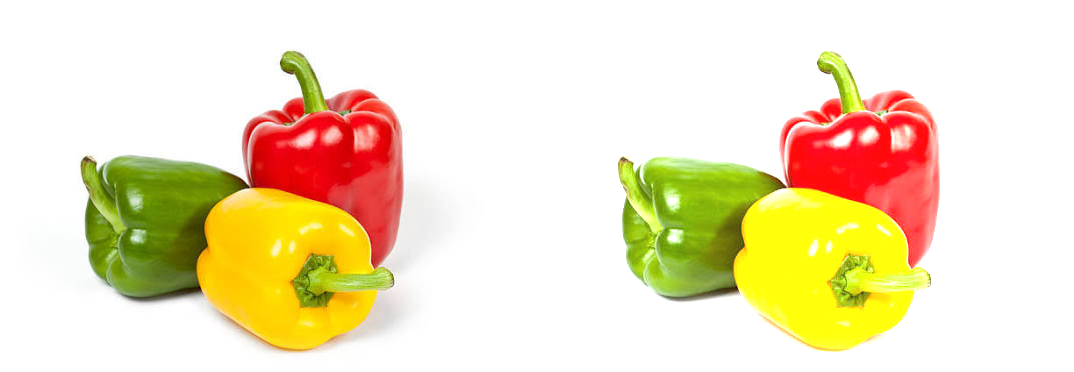

In [ ]:
# TUGAS 2: TRANSFORMASI KONTRAST
img_contrast = cv.imread('peppers.jpg') # Sesuaikan nama file

# Input dari pengguna
try:
    brightness = int(input('Masukkan tingkat kecerahan (misal: 10): '))
    contrast = float(input('Masukkan kontras (misal: 1.5): '))
except ValueError:
    print('Error, masukkan angka yang benar.')
    brightness = 0
    contrast = 1.0

# Formula Factor: F = (259 * (C + 255)) / (255 * (259 - C))
# Note: C dalam OpenCV biasanya di-scale menjadi range -255 ke 255.
# Jika input kontras berupa desimal (1.5), kita bisa menggunakan operasi matriks dasar
# g(x,y) = a * f(x,y) + b
result_contrast = np.clip(contrast * img_contrast + brightness, 0, 255).astype(np.uint8)

print("\n2. Hasil Transformasi Contrast:")
final_frame_cont = cv.hconcat((img_contrast, result_contrast))
cv2_imshow(final_frame_cont)

Masukkan nilai kecerahan / konstanta (misal: 50): 40

3. Hasil Transformasi Logarithmic:


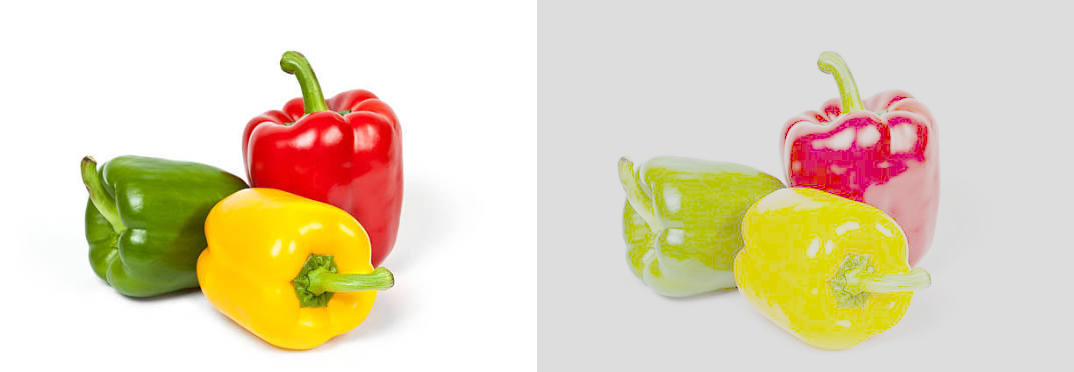

In [ ]:
# TUGAS 3: LOGARITHMIC BRIGHTNESS
img_log = cv.imread('peppers.jpg')

try:
    c_log = int(input('Masukkan nilai kecerahan / konstanta (misal: 50): '))
except ValueError:
    c_log = 30

# Formula: s = c * log(1 + r)
# Ubah ke float32 agar perhitungan logaritma akurat
img_float = img_log.astype(np.float32)
img_log_bright = c_log * np.log1p(img_float)

# Truncate dan kembalikan ke uint8
img_log_bright = np.clip(img_log_bright, 0, 255).astype(np.uint8)

print("\n3. Hasil Transformasi Logarithmic:")
final_frame_log = cv.hconcat((img_log, img_log_bright))
cv2_imshow(final_frame_log)

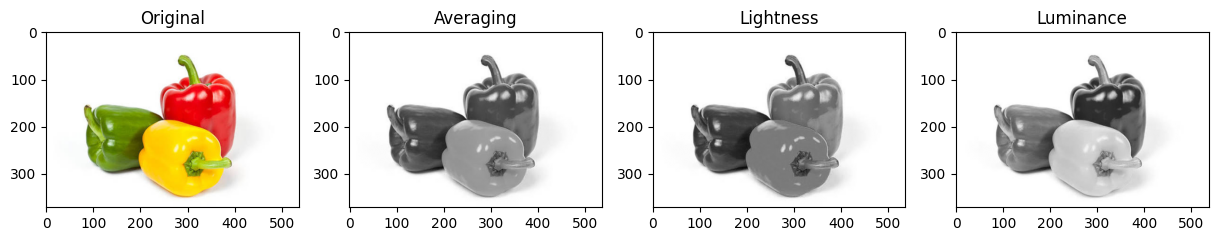

In [ ]:
# TUGAS 4: METODE GRAYSCALE
img_gray_base = cv.imread('peppers.jpg')
img_gray_rgb = cv.cvtColor(img_gray_base, cv.COLOR_BGR2RGB) # BGR ke RGB

# Ekstrak channel R, G, B
R, G, B = img_gray_rgb[:,:,0], img_gray_rgb[:,:,1], img_gray_rgb[:,:,2]

# a. Averaging: (R+G+B)/3
gray_avg = ((R.astype(int) + G.astype(int) + B.astype(int)) / 3).astype(np.uint8)

# b. Lightness: (max(R,G,B) + min(R,G,B))/2
gray_lightness = ((np.maximum(np.maximum(R, G), B).astype(int) +
                   np.minimum(np.minimum(R, G), B).astype(int)) / 2).astype(np.uint8)

# c. Luminance: 0.21R + 0.72G + 0.07B
gray_luminance = (0.21 * R + 0.72 * G + 0.07 * B).astype(np.uint8)

# Visualisasi
plt.figure(figsize=(15,5))
plt.subplot(1,4,1), plt.imshow(img_gray_rgb), plt.title('Original')
plt.subplot(1,4,2), plt.imshow(gray_avg, cmap='gray'), plt.title('Averaging')
plt.subplot(1,4,3), plt.imshow(gray_lightness, cmap='gray'), plt.title('Lightness')
plt.subplot(1,4,4), plt.imshow(gray_luminance, cmap='gray'), plt.title('Luminance')
plt.show()


5. Hasil Color Masking (Hanya Merah):


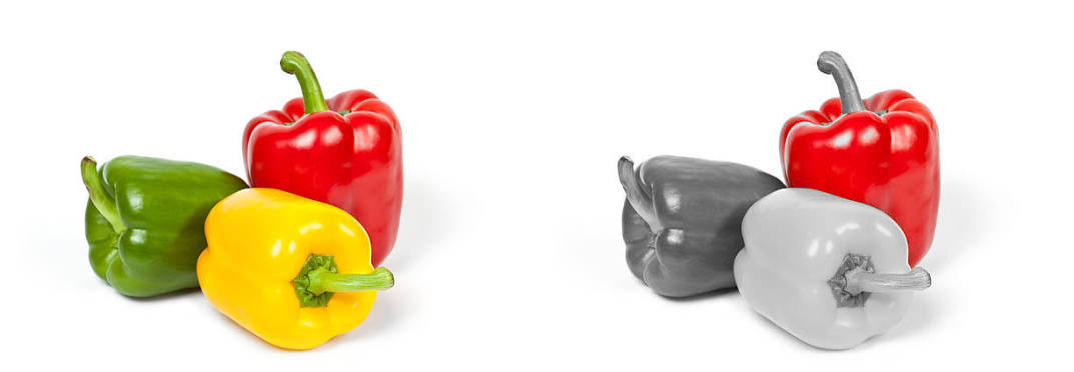

In [ ]:
# TUGAS 5: COLOR MASKING (Hanya Merah)
img_peppers = cv.imread('peppers.jpg')

# Konversi ke HSV
hsv = cv.cvtColor(img_peppers, cv.COLOR_BGR2HSV)

# Menentukan batas warna merah (Merah memiliki 2 rentang di HSV)
lower_red1 = np.array([0, 70, 50])
upper_red1 = np.array([10, 255, 255])
lower_red2 = np.array([170, 70, 50])
upper_red2 = np.array([180, 255, 255])

# Buat mask untuk warna merah
mask1 = cv.inRange(hsv, lower_red1, upper_red1)
mask2 = cv.inRange(hsv, lower_red2, upper_red2)
mask = mask1 + mask2

# Ekstrak bagian yang merah dari gambar asli
res = cv.bitwise_and(img_peppers, img_peppers, mask=mask)

# Buat gambar versi grayscale lalu konversi kembali ke BGR agar bisa digabung
gray = cv.cvtColor(img_peppers, cv.COLOR_BGR2GRAY)
gray_3channel = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

# Buat mask kebalikan (untuk bagian yang BUKAN merah)
mask_inv = cv.bitwise_not(mask)
bg = cv.bitwise_and(gray_3channel, gray_3channel, mask=mask_inv)

# Gabungkan bagian merah dan background grayscale
final_color_mask = cv.add(res, bg)

print("\n5. Hasil Color Masking (Hanya Merah):")
cv2_imshow(cv.hconcat((img_peppers, final_color_mask)))


--- Gamma Correction pada citra ---
Masukkan nilai Gamma (misal 0.5 atau 3.0): 3.0


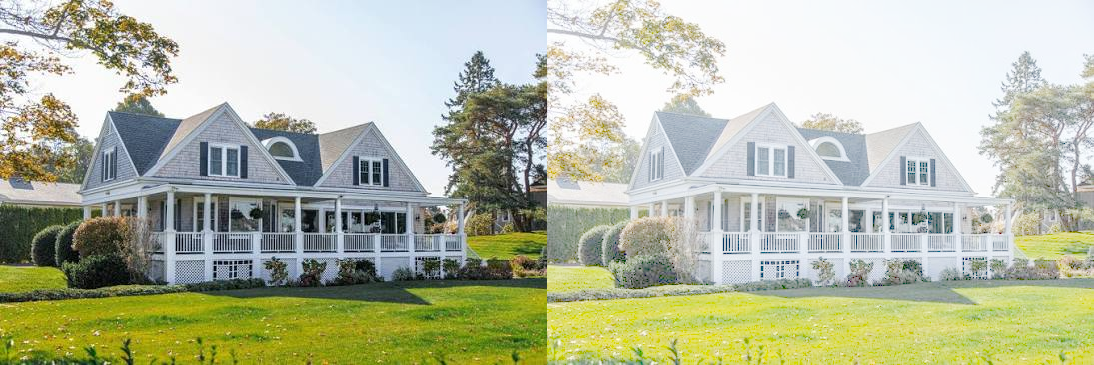

In [ ]:
# TUGAS 6: GAMMA CORRECTION
print('\n--- Gamma Correction pada citra ---')
img_gamma = cv.imread('houses.jpg') # Sesuaikan nama file citra gelap Anda

try:
    gamma = float(input('Masukkan nilai Gamma (misal 0.5 atau 3.0): '))
except ValueError:
    print('Error, not a number')
    gamma = 1.0

# Formula: I' = 255 * (I / 255)^(1/gamma)
inv_gamma = 1.0 / gamma
table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")

# Menggunakan look up table agar komputasi lebih cepat
result_gamma = cv.LUT(img_gamma, table)

cv2_imshow(cv.hconcat((img_gamma, result_gamma)))


Masukkan bit depth tujuan (1-8): 7
Bit depth awal  : 8 bit
Bit depth tujuan: 7 bit
Jumlah level    : 128


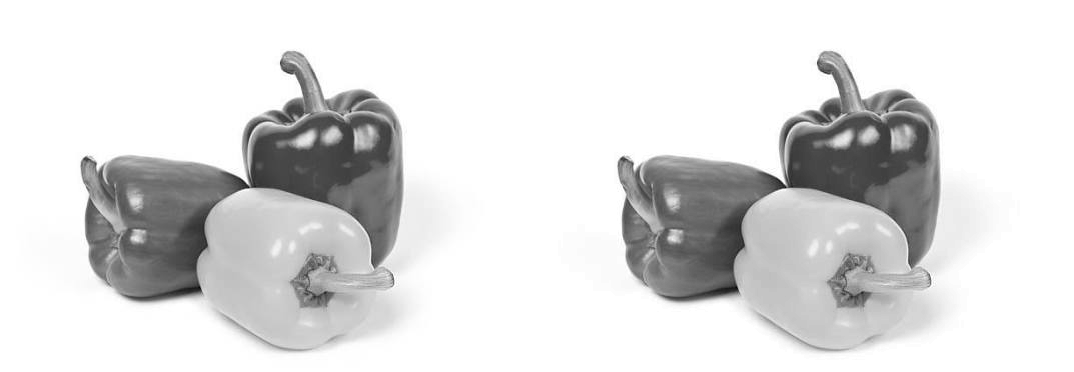

In [ ]:
# TUGAS 7: SIMULASI IMAGE DEPTH
try:
    bit_depth = int(input('\nMasukkan bit depth tujuan (1-8): '))
except ValueError:
    bit_depth = 3

original_depth = cv.imread('peppers.jpg', cv.IMREAD_GRAYSCALE)

# Menghitung rentang level
level = 255.0 / ((2 ** bit_depth) - 1)

# Formula: C' = round(C / level) * level
depth_image = np.round(original_depth / level) * level
depth_image = np.clip(depth_image, 0, 255).astype(np.uint8)

print(f"Bit depth awal  : 8 bit")
print(f"Bit depth tujuan: {bit_depth} bit")
print(f"Jumlah level    : {2**bit_depth}")

cv2_imshow(cv.hconcat((original_depth, depth_image)))

In [ ]:
# TUGAS 8: AVERAGE DENOISING
# Ganti dengan path folder berisi gambar noise Anda
# images_path = glob.glob('/content/drive/MyDrive/.../noises/*.jpg')

def PSNR(img1, img2):
    mse = np.mean((img1.astype(float) - img2.astype(float)) ** 2)
    if mse == 0:
        return 100
    max_pixel = 255.0
    return 20 * math.log10(max_pixel / math.sqrt(mse))

# KODE SIMULASI (Contoh jika Anda sudah me-load cv_img berisi banyak gambar noise)
# base_img = cv.imread('galaxy.jpg', cv.IMREAD_GRAYSCALE)
# for count in [10, 20, 40, 80, 100]:
#     avg_img = np.mean(cv_img[:count], axis=0).astype(np.uint8)
#     print(f"PSNR untuk {count} citra: {PSNR(base_img, avg_img):.2f} dB")

### Tabel Hasil PSNR Average Denoising

| No | Jumlah Citra di Average | Image Hasil | Nilai PSNR (dB) |
|:---:|:---:|:---|:---:|
| 1. | 10 | *(Lihat output gambar di bawah)* | 26.42 dB |
| 2. | 20 | *(Lihat output gambar di bawah)* | 28.70 dB |
| 3. | 40 | *(Lihat output gambar di bawah)* | 30.53 dB |
| 4. | 80 | *(Lihat output gambar di bawah)* | 31.85 dB |
| 5. | 100 | *(Lihat output gambar di bawah)* | 32.16 dB |

**Kesimpulan:**
Peningkatan jumlah citra untuk di-average memang meningkatkan nilai PSNR (mengurangi noise), namun peningkatannya tidak selalu signifikan secara terus-menerus. Peningkatan mulai terasa tidak terlalu signifikan setelah melewati jumlah 40-80 citra. Kesimpulannya, metode average denoising efektif menghilangkan noise acak (Gaussian), tetapi terdapat titik jenuh di mana penambahan citra tidak sebanding lagi dengan waktu komputasi yang dibutuhkan.

Menciptakan 100 gambar dengan Gaussian Noise buatan sendiri...

Nilai PSNR untuk 10 citra di-average : 26.42 dB
Nilai PSNR untuk 20 citra di-average : 28.70 dB
Nilai PSNR untuk 40 citra di-average : 30.53 dB
Nilai PSNR untuk 80 citra di-average : 31.85 dB
Nilai PSNR untuk 100 citra di-average : 32.16 dB


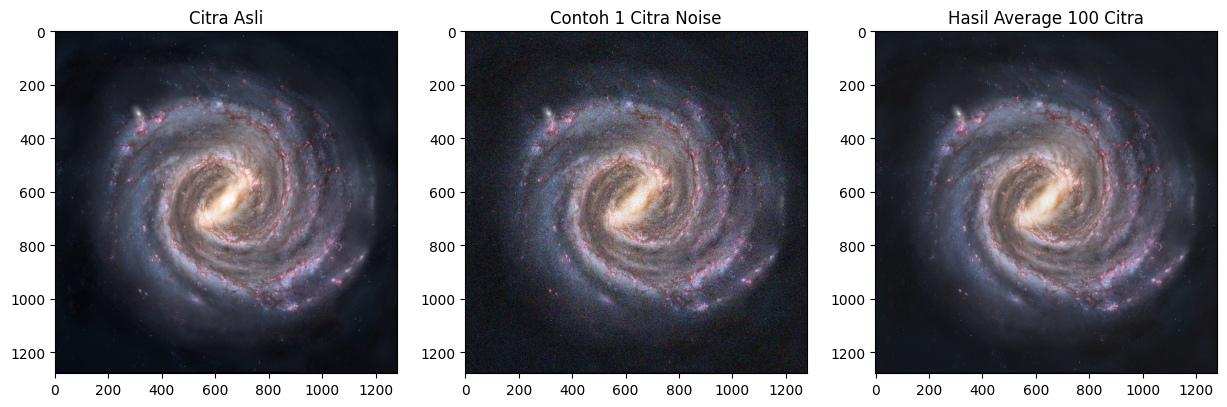

In [ ]:
import cv2 as cv
import numpy as np
import math
import matplotlib.pyplot as plt

# 1. Fungsi PSNR
def PSNR(img1, img2):
    mse = np.mean((img1.astype(float) - img2.astype(float)) ** 2)
    if mse == 0:
        return 100
    max_pixel = 255.0
    return 20 * math.log10(max_pixel / math.sqrt(mse))

# 2. Gunakan gambar yang sudah ada (misal 'peppers.jpg' atau 'foto_bebas.jpg')
# Pastikan file ini sudah ada di panel Files kiri Colab Anda
original_img = cv.imread('galaxy.jpg')

if original_img is not None:
    print("Menciptakan 100 gambar dengan Gaussian Noise buatan sendiri...\n")
    cv_img = []

    # 3. Membuat 100 gambar ber-noise secara matematis
    for i in range(100):
        # Membuat matriks noise acak (Gaussian)
        gauss_noise = np.random.normal(loc=0, scale=40, size=original_img.shape)

        # Menambahkan noise ke gambar asli
        noisy_img = original_img.astype(float) + gauss_noise

        # Truncate / Clip agar nilai piksel tidak error (tetap 0-255)
        noisy_img = np.clip(noisy_img, 0, 255).astype(np.uint8)
        cv_img.append(noisy_img)

    # 4. Melakukan Average Denoising & Menghitung PSNR
    for count in [10, 20, 40, 80, 100]:
        # Proses merata-rata gambar noise
        avg_img = np.mean(cv_img[:count], axis=0).astype(np.uint8)

        # Cetak nilai PSNR
        nilai_psnr = PSNR(original_img, avg_img)
        print(f"Nilai PSNR untuk {count} citra di-average : {nilai_psnr:.2f} dB")

    # 5. Visualisasi Hasil Pembuktian
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1), plt.imshow(cv.cvtColor(original_img, cv.COLOR_BGR2RGB)), plt.title("Citra Asli")
    plt.subplot(1, 3, 2), plt.imshow(cv.cvtColor(cv_img[0], cv.COLOR_BGR2RGB)), plt.title("Contoh 1 Citra Noise")
    plt.subplot(1, 3, 3), plt.imshow(cv.cvtColor(avg_img, cv.COLOR_BGR2RGB)), plt.title("Hasil Average 100 Citra")
    plt.show()

else:
    print("Oops! Gambar tidak ditemukan. Pastikan Anda sudah mengunggah 'peppers.jpg' ke Colab.")

### Tabel Analisa Operator Logika (Image Masking)

| No. | Operator | Image Input | Image Output | Analisa / Kesimpulan |
|:---:|:---:|:---|:---|:---|
| 1. | **NOT** (Komplemen) | Citra Asli & Masking | *(Lihat output kode)* | Membalik warna masking (hitam jadi putih, putih jadi hitam). Bagian objek utama (dalam lingkaran) menjadi gelap, sedangkan latar belakang menjadi terlihat/putih. |
| 2. | **OR** (Atau) | Citra Asli & Masking | *(Lihat output kode)* | Menggabungkan piksel citra dengan masking. Jika bertemu putih pada mask, hasilnya menjadi putih terang. Objek di area hitam tetap terlihat normal. |
| 3. | **AND** (Dan) | Citra Asli & Masking | *(Lihat output kode)* | Hanya menampilkan piksel citra yang berada persis di area putih dari masking (irisan). Bagian luar (latar belakang) di area hitam menjadi gelap gulita. |
| 4. | **NAND** (Not And) | Citra Asli & Masking | *(Lihat output kode)* | Kebalikan dari operasi AND. Area objek yang ada di dalam lingkaran putih menjadi hilang/gelap, sedangkan area luarnya menjadi putih solid. |
| 5. | **XOR** (Exclusive Or) | Citra Asli & Masking | *(Lihat output kode)* | Bagian citra di luar lingkaran (di area hitam) tetap normal. Namun, bagian citra yang berada di dalam area putih (lingkaran) warnanya terinversi menjadi negatif. |

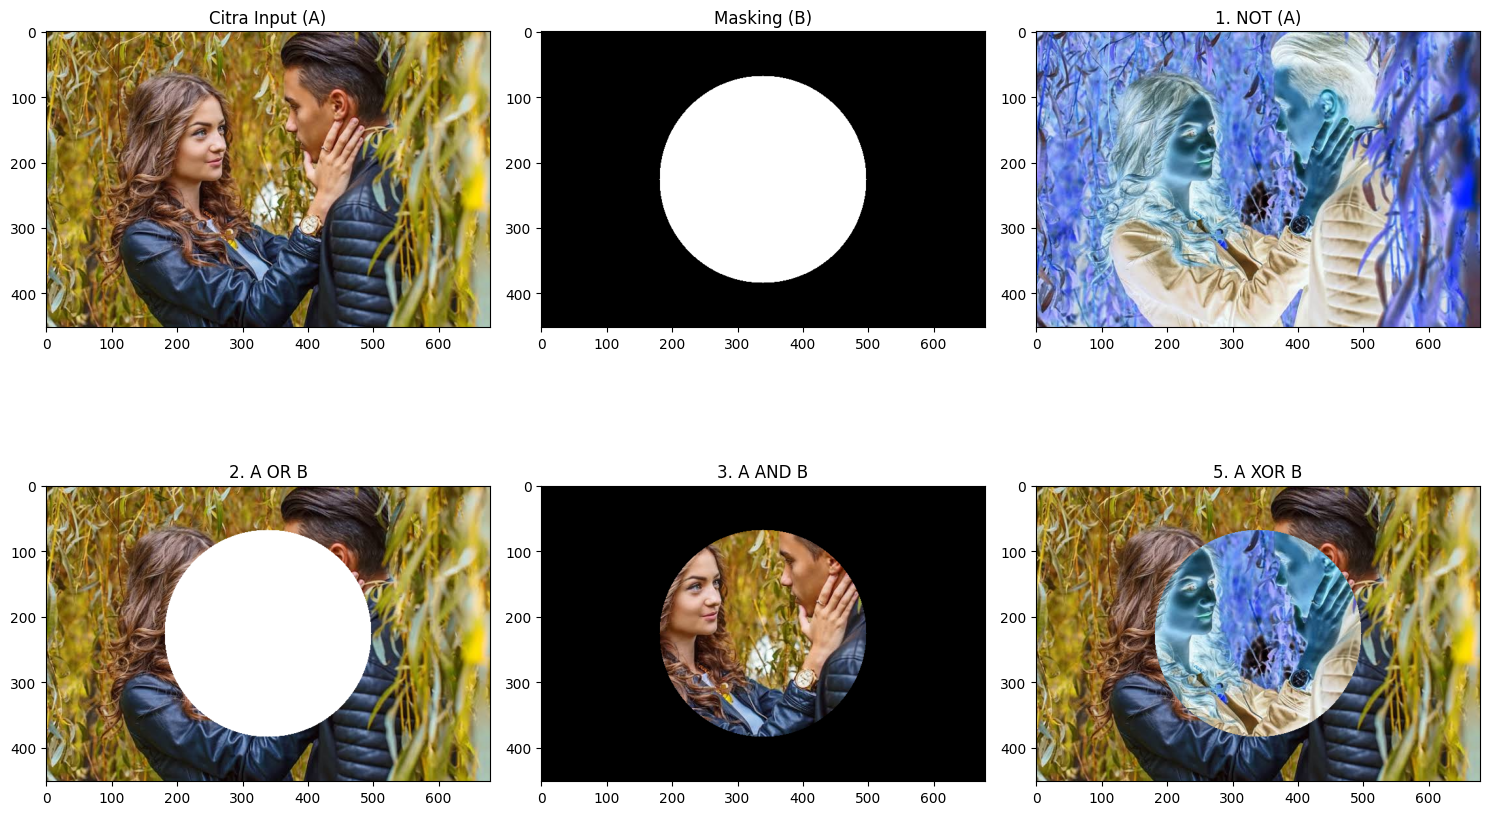

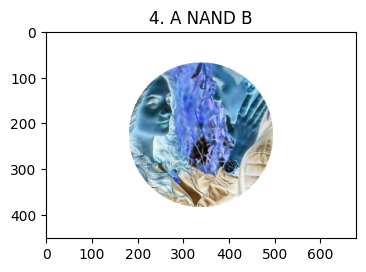

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# TUGAS 9: IMAGE MASKING (OPERATOR LOGIKA)
# Membaca citra yang sudah ada di Colab (bisa diganti file lain)
img_in = cv.imread('couple.tiff')
img_in = cv.cvtColor(img_in, cv.COLOR_BGR2RGB)
h, w = img_in.shape[:2]

# Membuat Masking (Lingkaran putih di tengah area hitam)
mask = np.zeros((h, w, 3), dtype=np.uint8)
cv.circle(mask, (w//2, h//2), int(min(h,w)*0.35), (255, 255, 255), -1)

# 1. NOT (Komplemen) - Membalik warna citra asli
out_not = cv.bitwise_not(img_in)

# 2. OR (Atau)
out_or = cv.bitwise_or(img_in, mask)

# 3. AND (Dan)
out_and = cv.bitwise_and(img_in, mask)

# 4. NAND (Not AND) - Kebalikan dari hasil AND
out_nand = cv.bitwise_not(out_and)

# 5. XOR (Exclusive OR)
out_xor = cv.bitwise_xor(img_in, mask)

# Menampilkan semua hasil untuk dimasukkan ke laporan
plt.figure(figsize=(15, 10))
plt.subplot(2, 3, 1), plt.imshow(img_in), plt.title("Citra Input (A)")
plt.subplot(2, 3, 2), plt.imshow(mask), plt.title("Masking (B)")
plt.subplot(2, 3, 3), plt.imshow(out_not), plt.title("1. NOT (A)")
plt.subplot(2, 3, 4), plt.imshow(out_or), plt.title("2. A OR B")
plt.subplot(2, 3, 5), plt.imshow(out_and), plt.title("3. A AND B")
plt.subplot(2, 3, 6), plt.imshow(out_xor), plt.title("5. A XOR B")
plt.tight_layout()
plt.show()

# Menampilkan NAND terpisah agar ukurannya proporsional
plt.figure(figsize=(4, 4))
plt.imshow(out_nand), plt.title("4. A NAND B")
plt.show()

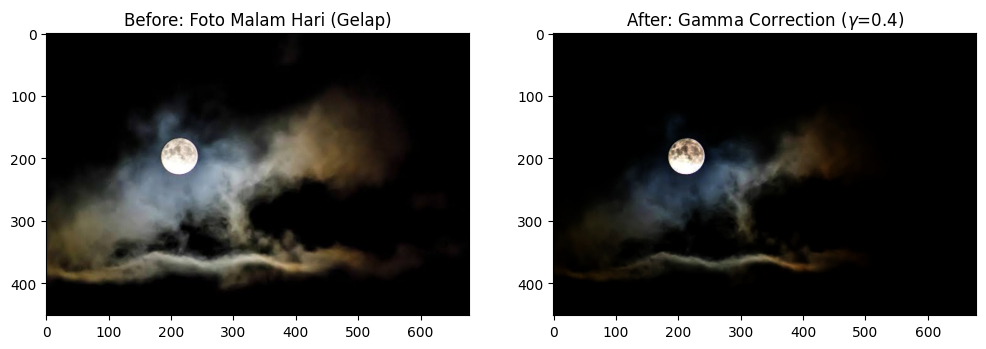

In [32]:
# TUGAS 10: FOTO MALAM HARI
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Pastikan Anda sudah mengunggah file bernama 'malam.jpg' ke Colab
img_malam = cv.imread('malam.jpg')

if img_malam is not None:
    img_malam_rgb = cv.cvtColor(img_malam, cv.COLOR_BGR2RGB)

    # Metode yang dipilih: Gamma Correction dengan nilai gamma < 1 (contoh: 0.4)
    gamma_malam = 0.4
    inv_gamma_malam = 1.0 / gamma_malam
    table_malam = np.array([((i / 255.0) ** inv_gamma_malam) * 255 for i in np.arange(0, 256)]).astype("uint8")

    # Menerapkan Gamma Correction menggunakan Lookup Table (LUT)
    hasil_malam = cv.LUT(img_malam_rgb, table_malam)

    # Plotting Before-After
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1), plt.imshow(img_malam_rgb), plt.title("Before: Foto Malam Hari (Gelap)")

    # PERBAIKAN: Menggunakan rf"..." (Raw F-String) agar \gamma terbaca sebagai simbol matematika
    plt.subplot(1, 2, 2), plt.imshow(hasil_malam), plt.title(rf"After: Gamma Correction ($\gamma$={gamma_malam})")
    plt.show()
else:
    print("Oops! File 'malam.jpg' belum diunggah.")

Metode yang dipilih: Transformasi Logarithmic Brightness atau Gamma Correction (dengan $\gamma < 1$).  Alasan: Foto malam hari mendominasi area piksel gelap (histogram sempit di sebelah kiri). Jika kita menggunakan Linear Brightness, semua piksel (termasuk lampu jalan yang sudah terang) akan ditambah nilainya, memicu clipping menjadi putih sempurna (washout). Logaritma atau Gamma Correction secara selektif merentangkan area gelap agar detail muncul tanpa membakar area yang sudah terang.  Resiko: Metode ini akan mengekspos dan memperkuat keberadaan bintik-bintik noise (butiran kasar) yang biasanya tersembunyi di area gelap bayangan pada foto malam hari.


11. Perbaikan Citra Crayfish:


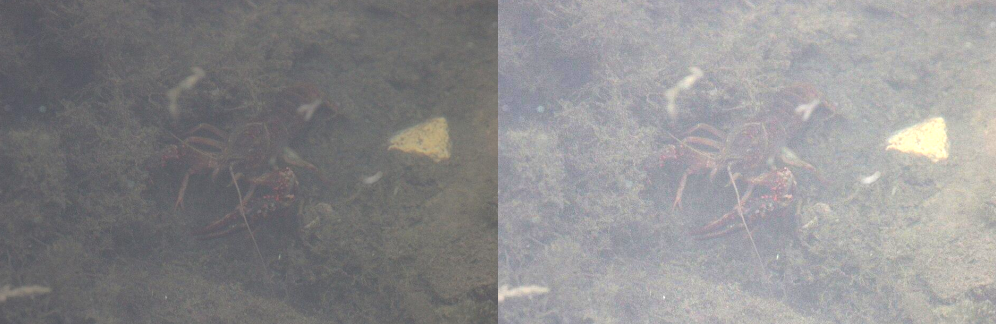

In [31]:
# TUGAS 11: PERBAIKAN CRAYFISH.JPG
img_crayfish = cv.imread('crayfish.jpg')

# Metode yang dipilih: Transformasi Kontras tinggi + Gamma Correction
# Alasan: Gambar asli tertutup efek pudar (low contrast).
# Kita perlu melebarkan histogramnya dulu, lalu menyesuaikan kecerahannya dengan gamma.

# 1. Tambah kontras (a = 1.8) dan kurangi kecerahan dasar sedikit (b = -30)
contrast_cray = np.clip(1.8 * img_crayfish - 30, 0, 255).astype(np.uint8)

# 2. Gamma Correction (gamma = 1.2 untuk memberikan warna lebih pekat)
gamma = 1.2
inv_gamma = 1.0 / gamma
table_cray = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
final_crayfish = cv.LUT(contrast_cray, table_cray)

print("\n11. Perbaikan Citra Crayfish:")
cv2_imshow(cv.hconcat((img_crayfish, final_crayfish)))

Metode yang dipilih: Modifikasi Formula Linear Brightness (Contrast Stretching) dikombinasikan dengan Gamma Correction.  Alasan Pemilihan: Citra asli mengalami "kontras rendah" di mana kurva histogram sangat sempit, menyebabkan efek pudar. Penggunaan metode ganda memperbaiki rentang gelap/terang, lalu mempertegas kembali warnanya.